Shape: (20640, 9)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0   8.325      41.0     6.984      1.024       322.0     2.556     37.88   
1   8.301      21.0     6.238      0.972      2401.0     2.110     37.86   
2   7.257      52.0     8.288      1.073       496.0     2.802     37.85   
3   5.643      52.0     5.817      1.073       558.0     2.548     37.85   
4   3.846      52.0     6.282      1.081       565.0     2.181     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422   

Missing values: {'MedInc': 0, 'HouseAge': 0, 'AveRooms': 0, 'AveBedrms': 207, 'Population': 0, 'AveOccup': 0, 'Latitude': 0, 'Longitude': 0, 'MedHouseVal': 0}

MSE : 0.5558
RMSE : 0.7455
R2 : 0.5759

Intercept: 2.0719
Coefficients:
 MedInc        0.8544
HouseAge      0.1225
AveRooms     -0.2944
AveBedrms     0.3393
Population   -0.0023
AveOccup     -0.0

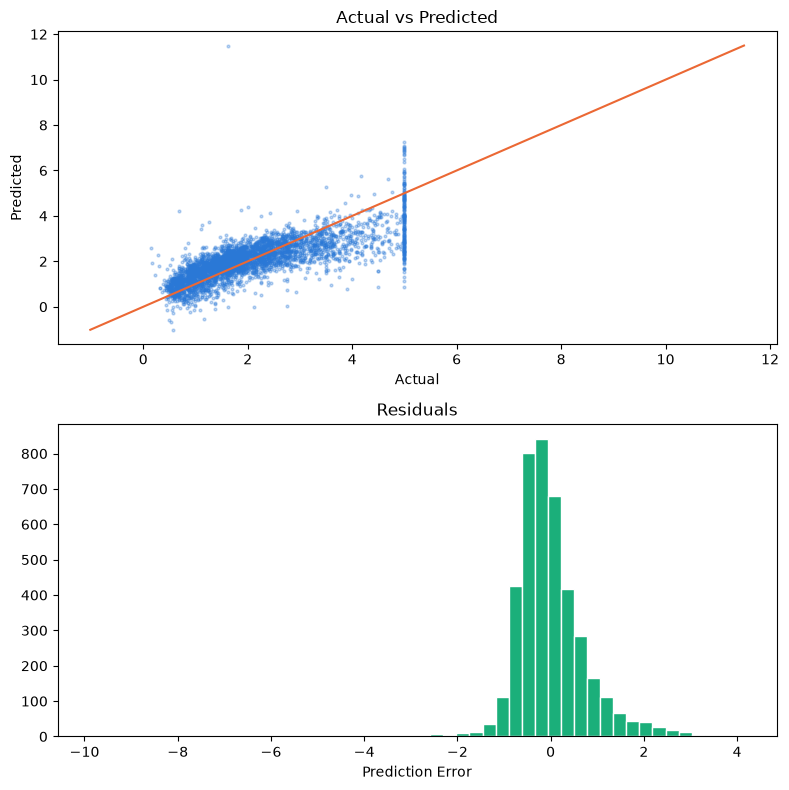

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load California Housing dataset (OFFLINE)
raw = pd.read_csv("housing.csv")

# 2. Prepare required features
df = pd.DataFrame({
    "MedInc": raw["median_income"],
    "HouseAge": raw["housing_median_age"],
    "AveRooms": raw["total_rooms"] / raw["households"],
    "AveBedrms": raw["total_bedrooms"] / raw["households"],
    "Population": raw["population"],
    "AveOccup": raw["population"] / raw["households"],
    "Latitude": raw["latitude"],
    "Longitude": raw["longitude"],
    "MedHouseVal": raw["median_house_value"] / 100000
})

print("Shape:", df.shape)
print(df.head().round(3), "\n")
print("Missing values:", df.isnull().sum().to_dict())

# 3. Split features and target
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

# 4. Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Handle missing values using training median
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

# 6. Feature Scaling
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# 7. Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 8. Predict house prices
y_pred = model.predict(X_test)

# 9. Model Evaluation
mse = mean_squared_error(y_test, y_pred)

print("\nMSE : %.4f" % mse)
print("RMSE : %.4f" % np.sqrt(mse))
print("R2 : %.4f" % r2_score(y_test, y_pred))

print("\nIntercept: %.4f" % model.intercept_)
print("Coefficients:\n",
      pd.Series(model.coef_, index=X.columns).round(4).to_string())

# 10. Visualization
fig, ax = plt.subplots(2, 1, figsize=(8, 8))

ax[0].scatter(y_test, y_pred, s=4,
              alpha=0.3, color="#2a78d6")

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]
ax[0].plot(limits, limits, color="#eb6834")

ax[0].set_xlabel("Actual")
ax[0].set_ylabel("Predicted")
ax[0].set_title("Actual vs Predicted")

ax[1].hist(y_test - y_pred, bins=50,
           color="#1baf7a", edgecolor="white")

ax[1].set_title("Residuals")
ax[1].set_xlabel("Prediction Error")

plt.tight_layout()
plt.show()
